# Milestone 3: Model Comparison

This notebook compares three regression models:
- Median dummy regressor: a simple reference prediction.
- Linear regression: learns a weighted relationship between inputs
  and rental price.
- Decision tree regressor: learns rules that can capture nonlinear
  relationships.

## 1. Load and select the data

Only monthly USD listings are retained, matching Milestone 2.
Previously flagged suspicious records remain unchanged for this
initial comparison.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/apartments_for_rent_classified_10K.csv",
    sep=";",
    encoding="latin1"
)

data = df.loc[
    (df["price_type"] == "Monthly") &
    (df["currency"] == "USD")
].copy()

print("Original listings:", len(df))
print("Retained listings:", len(data))

Original listings: 10000
Retained listings: 9998


## 2. Input features and target

Eight inputs as decided in milestone 2:

In [2]:
numeric_features = [
    "bedrooms",
    "bathrooms",
    "square_feet",
    "latitude",
    "longitude"
]

categorical_features = [
    "cityname",
    "state",
    "has_photo"
]

features = numeric_features + categorical_features

X = data[features].copy()
y = data["price"].copy()

print("Input table shape:", X.shape)
print("Target shape:", y.shape)

Input table shape: (9998, 8)
Target shape: (9998,)


## 3. Evaluation of design

The same random 80/20 split from Milestone 2 is used, with a fixed seed of 42. All three models will be compared on the same five cross-validation folds using development data only. The final test set remains unused.
Possible repeated property listings are still a limitation of the random split.

In [3]:
from sklearn.model_selection import train_test_split, KFold

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Development listings:", len(X_dev))
print("Protected test listings:", len(X_test))

Development listings: 7998
Protected test listings: 2000


## 4. Preprocessing

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# will fill missing numerical values with the median for that column learned from the training data
numeric_pipeline = SimpleImputer(strategy="median")

# this pipeline fills missing values with 'unknown' and then uses hot encoder to turn categories like city or state into indicators
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# this will send each set of columns through the right steps and will combine results
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## 5. Model for comparison

In [9]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# dummy will predict the training median rent
# linear regression will learn a weighted combination of features
# decision tree learns rules that split listings into groups
models = {
    "Median dummy": DummyRegressor(strategy="median"),
    "Linear regression": LinearRegression(),
    "Decision tree": DecisionTreeRegressor(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    )
}

model_pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Models:", list(model_pipelines))

Models: ['Median dummy', 'Linear regression', 'Decision tree']


In [7]:
from sklearn.model_selection import cross_validate

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error"
}

results = []

for name, pipeline in model_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        error_score="raise"
    )

    mae = -scores["test_MAE"]
    rmse = -scores["test_RMSE"]

    results.append({
        "Model": name,
        "Mean MAE": mae.mean(),
        "MAE std": mae.std(ddof=1),
        "Mean RMSE": rmse.mean(),
        "RMSE std": rmse.std(ddof=1)
    })

print(f"Evaluated {len(results)} models.")

Evaluated 3 models.


In [8]:
comparison = pd.DataFrame(results).sort_values("Mean MAE")
display(comparison.round(2))

,Model,Mean MAE,MAE std,Mean RMSE,RMSE std
1,Linear regression,328.57,17.51,732.64,363.73
2,Decision tree,395.13,18.63,835.43,326.61
0,Median dummy,556.46,32.80,1115.79,310.15


### Initial model comparison

Linear regression performed best in five fold cross-validation, with a mean MAE of 328.57 dollars and a mean RMSE of 732.64 dollars. Its mean MAE was about 41% lower than the median dummy baseline. The decision tree also improved on the baseline, but its initial settings produced a higher mean MAE and RMSE than linear regression.

These results are from the development folds.
The protected test set was not used

## 6. Decision tree tuning

Ill compare different maximum depths and minimum leaf sizes to see whether a more or less complex tree reduces validation MAE.

In [10]:
from sklearn.model_selection import GridSearchCV

tree_settings = {
    "model__max_depth": [3, 5, 10, None],
    "model__min_samples_leaf": [5, 20, 50]
}

tree_search = GridSearchCV(
    estimator=model_pipelines["Decision tree"],
    param_grid=tree_settings,
    scoring=scoring,
    refit="MAE",
    cv=cv,
    error_score="raise"
)

tree_search.fit(X_dev, y_dev)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [5, 20, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'MAE'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter do

In [11]:
best_row = tree_search.best_index_

print("Selected settings:", tree_search.best_params_)
print(f"Mean validation MAE: ${-tree_search.best_score_:,.2f}")
print(
    f"Mean validation RMSE: "
    f"${-tree_search.cv_results_['mean_test_RMSE'][best_row]:,.2f}"
)

Selected settings: {'model__max_depth': None, 'model__min_samples_leaf': 5}
Mean validation MAE: $322.87
Mean validation RMSE: $770.72


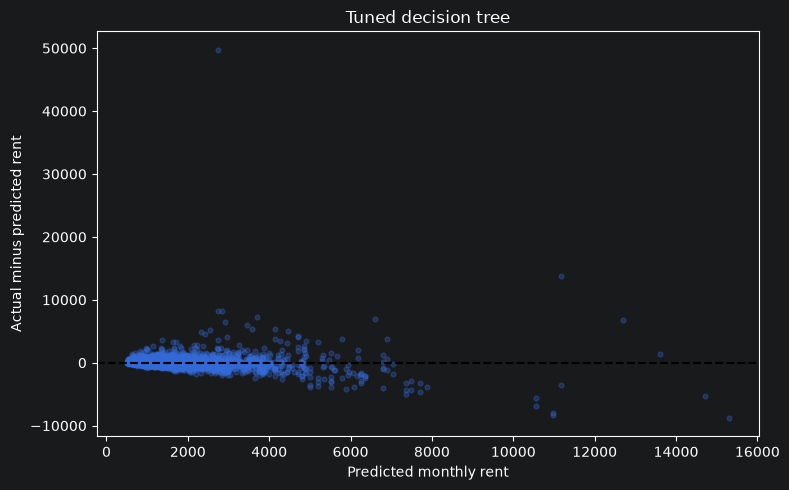

In [13]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict

tree_predictions = cross_val_predict(
    tree_search.best_estimator_,
    X_dev,
    y_dev,
    cv=cv
)

residuals = y_dev - tree_predictions

plt.figure(figsize=(8, 5))
plt.scatter(tree_predictions, residuals, alpha=0.3, s=12)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted monthly rent")
plt.ylabel("Actual minus predicted rent")
plt.title("Tuned decision tree")
plt.tight_layout()
plt.show()

In [14]:
error_details = pd.DataFrame({
    "actual_rent": y_dev,
    "predicted_rent": tree_predictions,
    "residual": residuals,
    "absolute_error": residuals.abs()
})

display(error_details.nlargest(5, "absolute_error").round(2))

,actual_rent,predicted_rent,residual,absolute_error
8829,52500,2750.0,49750.0,49750.0
9996,25000,11180.0,13820.0,13820.0
9980,6500,15300.0,-8800.0,8800.0
8594,2695,10972.0,-8277.0,8277.0
8573,11000,2750.0,8250.0,8250.0


### What this shows

The tuned decision tree’s largest error was on a listing with a recorded monthly rent of 52500 dollars. The model predicted 2750, an underprediction of 49,750. The data audit found that the listing description mentioned 500 dollars per month, so the recorded price may be incorrect. The record was retained, and an error this large can have a substantial effect on RMSE.

Other large errors went in both directions. For example, the tree predicted 11180 for a 25,000 listing and 15300 for a 6500 listing. These examples show that the tree can substantially underpredict or overpredict individual rents. The analysis uses development folds only; the protected test set was not used.

## Draft conclusion

Both linear regression and the decision tree predicted monthly rent better than the median dummy baseline on the five development folds. The tuned decision tree had the lowest mean MAE at 322.87 per month, compared with 328.57 for linear regression and $556.46 for the dummy baseline. However, linear regression had a lower RMSE than the tuned tree (732.64 versus 770.72), so it performed better on the metric that gives more weight to large errors.

The tuned tree is the current leading model on MAE, but its $5.70 advantage over linear regression is small. The same folds were used to select the tree settings, so this result needs an independent check. The residual analysis also showed that the largest error involved a listing with a suspected recording error. In addition, repeated property listings may have crossed folds, which would make validation scores positive.